# 12 — The live 2026-27 Most Improved race

**Re-run this notebook whenever you want an update.** It downloads the newest game logs, rebuilds the race and redraws the charts.

**Question.** Who leads the 2026-27 Most Improved Player (MIP) race so far, and how much should we believe it at this point of the season?

**Decisions**
- **Same comparison as notebook 10:** this season's per-game numbers so far against each player's baseline season (most recent season with at least 33% of the games).
- **A model for each point of the season.** The model is trained on past seasons cut at the **same number of days after opening night**, so it has learned how much a few days of games say about the eventual winner. Season-long stats (usage, start rate, defensive rating) are left out, as in notebook 10's mid-season race.
- **Inputs:** changes in points, rebounds, assists, steals, blocks, minutes, game score and true shooting; relative change in points and game score; team win % change; age; second-year flag. Penalty λ = 3.
- **Candidates:** at least one previous NBA season, a baseline season, and at least half of his team's games so far. Previous winners are included.
- **Established scorers** are handled as in notebook 11: baseline scoring counts slightly for a player up to a turning point of 20 points a game and against him above it (decision D27, revised 30 October).
- **Age** is rolled forward from each player's latest season in our table, so players who missed 2025-26 (Tyrese Haliburton, Damian Lillard) still get one.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from nba_api.stats.endpoints import leaguegamelog
from unicorn.gamelogs import GAMELOG_SEASONS, build_game_table, load_game_logs, mip_candidates
from unicorn.labels import MIP_WINNERS
from unicorn.mip import AGE, GAMELOG_DEFENSE, GAMELOG_DELTAS, RELATIVE, SECOND_YEAR, TEAM, ChoiceModel
from unicorn.plotting import BLUE, FIG_DIR, INK, INK2, MUTED, ORANGE, SERIES, SURFACE, apply_style
from unicorn.raw import PROJECT_ROOT, fetch

warnings.filterwarnings("ignore")
apply_style()
LIVE, LIVE_START, L2 = "2026-27", 2026, 3.0
from unicorn.preseason import TURNING_POINT
TURN_LIVE = ["base_ppg", "base_ppg_over_turn"]   # baseline scoring, and points above the turning point (decision D27, revised)
EARLY = GAMELOG_DELTAS + GAMELOG_DEFENSE + RELATIVE + TEAM + AGE + SECOND_YEAR + TURN_LIVE

fetch(leaguegamelog.LeagueGameLog, refresh=True, season=LIVE, player_or_team_abbreviation="P", season_type_all_star="Regular Season")
games, _, _ = build_game_table(load_game_logs(GAMELOG_SEASONS + [LIVE]))
games["day"] = (games["game_date"] - games.groupby("season")["game_date"].transform("min")).dt.days
live_games = games[games["season"] == LIVE]
DAY_NOW = int(live_games["day"].max())
team_games = live_games.groupby("team_id")["game_id"].nunique()
print(f"{LIVE}: {live_games['game_id'].nunique()} games through {live_games['game_date'].max():%d %b %Y} "
      f"(day {DAY_NOW} after opening night); teams have played {team_games.min()}–{team_games.max()} games")

2026-27: 68 games through 28 Oct 2026 (day 8 after opening night); teams have played 3–5 games


In [2]:
# player table with a 2026-27 row: age and experience rolled forward from each player's latest season
ps = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "player_season.parquet")
latest = ps[ps["season_start"] < LIVE_START].sort_values("season_start").groupby("player_id").tail(1)
gap = LIVE_START - latest["season_start"]
ps_live = pd.concat([ps, latest[["player_id"]].assign(season_start=LIVE_START, age=latest["age"] + gap, exp=latest["exp"] + gap)], ignore_index=True)

first_win = {pid: int(s[:4]) for s, pid in sorted(MIP_WINNERS.items(), reverse=True)}

def race(day):
    """Eligible candidates in every season, using only games up to `day` days after that season's opener."""
    c = mip_candidates(games[games["day"] <= day], ps_live, min_prior_seasons=1, season_stats=False)
    c["second_year"] = (c["prior_seasons"] == 1).astype(float)
    c["mip"] = [MIP_WINNERS.get(s) == p for s, p in zip(c["season"], c["player_id"])]
    c["previous_winner"] = [first_win.get(p, 9999) < y for p, y in zip(c["player_id"], c["season_start"])]
    c["base_ppg_over_turn"] = (c["base_ppg"] - TURNING_POINT).clip(lower=0)
    return c[c["eligible"] & (c["season_start"] >= 2011)].reset_index(drop=True)   # previous winners included

now = race(DAY_NOW)
print("live candidates:", (now["season"] == LIVE).sum(), "| missing age:", now.loc[now["season"] == LIVE, "age"].isna().sum())

live candidates: 293 | missing age: 0


## 12A — How much can this many days tell us?

Before looking at the leaders: in past seasons, where did the **eventual winner** rank at the same point of the season? Each season is predicted by a model trained on the other seasons, cut at the same day.

In [3]:
def winner_ranks(day):
    c = now if day == DAY_NOW else race(day)
    h = c[c["season"] != LIVE]
    out = {}
    for s in sorted(h["season"].unique()):
        te = h[h["season"] == s]
        if not te["mip"].any():
            out[s] = np.nan          # the eventual winner had not yet played enough to be a candidate
            continue
        p = ChoiceModel(EARLY, L2).fit(h[h["season"] != s]).predict_proba(te)
        out[s] = p.rank(ascending=False, method="min")[te["mip"]].iloc[0]
    return pd.Series(out)

DAYS = sorted({2, DAY_NOW, 7, 14, 30, 60, 90, 120})
ranks = pd.DataFrame({d: winner_ranks(d) for d in DAYS})
curve = pd.DataFrame({"winner #1": (ranks == 1).sum(), "winner in top 3": (ranks <= 3).sum(), "winner in top 7": (ranks <= 7).sum(),
                      "winner in top 20": (ranks <= 20).sum(), "median winner rank": ranks.median()}).T
curve.columns = [f"day {d}" for d in DAYS]
print(f"out of {len(ranks)} past seasons (2011-12 → 2025-26)")
curve.round(1)

out of 15 past seasons (2011-12 → 2025-26)


,day 2,day 7,day 8,day 14,day 30,day 60,day 90,day 120
winner #1,0.0,3.0,3.0,1.0,3.0,5.0,7.0,7.0
winner in top 3,3.0,4.0,6.0,6.0,8.0,8.0,8.0,9.0
winner in top 7,4.0,6.0,8.0,8.0,8.0,11.0,11.0,12.0
winner in top 20,7.0,9.0,11.0,10.0,13.0,13.0,14.0,15.0
median winner rank,18.5,8.5,5.0,6.0,3.0,3.0,2.0,2.0


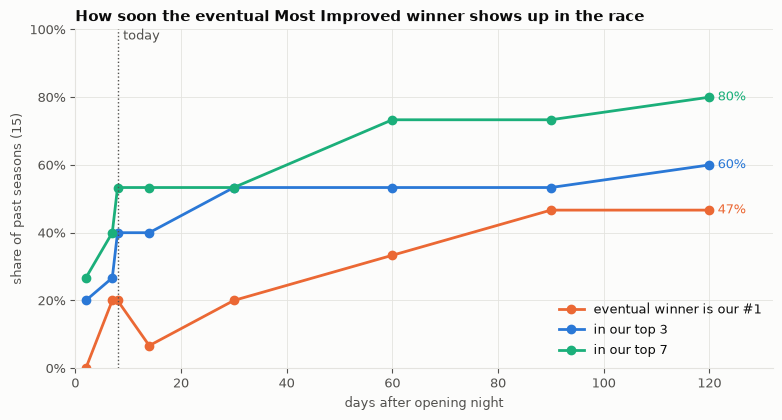

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.4))
n = len(ranks)
for (label, k), col in zip([("eventual winner is our #1", 1), ("in our top 3", 3), ("in our top 7", 7)], [ORANGE, BLUE, SERIES[2]]):
    share = [(ranks[d] <= k).sum() / n for d in DAYS]
    ax.plot(DAYS, share, marker="o", color=col, label=label)
    ax.annotate(f"{share[-1]:.0%}", (DAYS[-1], share[-1]), xytext=(6, 0), textcoords="offset points", va="center", fontsize=9, color=col)
ax.axvline(DAY_NOW, color=INK2, linewidth=1, linestyle=":")
ax.annotate("today", (DAY_NOW, 0.97), xytext=(4, 0), textcoords="offset points", fontsize=9, color=INK2)
ax.set_ylim(0, 1); ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); ax.set_xlim(0, DAYS[-1] + 12)
ax.set_xlabel("days after opening night"); ax.set_ylabel(f"share of past seasons ({n})")
ax.legend(frameon=False, loc="lower right")
ax.set_title("How soon the eventual Most Improved winner shows up in the race", loc="left")
fig.savefig(FIG_DIR / "12_race_by_day.png", dpi=150, bbox_inches="tight")

### 12A findings

- **After two days (one game for most teams), the race says very little.** The eventual winner was in our top 7 in 4 of 15 past seasons and never #1; median rank 18.5. That is no better than the preseason prediction in notebook 11.
- **After about a week (3–5 games) it starts to mean something:** at day 8 the winner was in our top 7 in 8 of 15 seasons, median rank 5.
- **By day 30 (about 14 games) the winner's median rank is 3; by day 60 he is in the top 7 in 11 of 15 seasons, and by day 120 in 12.** What keeps improving after that is the order at the top (#1 in 7 of 15 by day 90).
- **The scoring turning point (revised 30 October) traded ranks for fit at day 30:** the winner is in the top 7 in 8 of 15 seasons at day 30, against 11 before the change, but the chance the model gives the eventual winner is higher on average. With 15 seasons, a few winners moving in or out of the top 7 is within noise; it is flagged here because it is a real cost.
- **Rule of thumb:** treat the race as a rough shortlist after a week, a real shortlist after one to two months, and a real ranking from about the All-Star break.

## 12B — The race today

In [5]:
hist, T = now[now["season"] != LIVE], now[now["season"] == LIVE].copy()
model = ChoiceModel(EARLY, L2).fit(hist)
T["chance"] = model.predict_proba(T)
T = T.sort_values("chance", ascending=False).reset_index(drop=True)
T["rank"] = np.arange(1, len(T) + 1)

NICE = {"ppg_delta": "points", "rpg_delta": "rebounds", "apg_delta": "assists", "spg_delta": "steals", "bpg_delta": "blocks",
        "mpg_delta": "minutes", "game_score_delta": "game score", "ts_delta": "shooting efficiency", "ppg_rel": "points (relative)",
        "game_score_rel": "game score (relative)", "team_win_delta": "team winning more", "age": "age", "second_year": "second-year discount",
        "base_ppg": "baseline scoring", "base_ppg_over_turn": f"baseline points above {TURNING_POINT}"}
Z = pd.DataFrame(model._design(T), index=T.index, columns=EARLY)
contrib = ((Z - Z.mean()) * model.coef_).rename(columns=NICE)
T["why"] = [" + ".join(contrib.drop(columns=["second-year discount", f"baseline points above {TURNING_POINT}"]).loc[i].nlargest(2).index) for i in T.index]   # the discount is never a reason to pick someone
print("weights:", model.coefficients().rename(NICE).round(2).sort_values(ascending=False).to_dict())
cols = {"rank": "rank", "player_name": "player", "team": "team", "chance": "chance", "games": "games", "ppg": "points", "base_ppg": "points last season",
        "game_score": "game score", "base_game_score": "game score last season", "mpg": "minutes", "base_mpg": "minutes last season", "age": "age", "why": "main reasons"}
T.head(10)[list(cols)].rename(columns=cols).style.format({"chance": "{:.1%}"}, precision=1).hide(axis="index")

weights: {'points': 0.83, 'baseline scoring': 0.51, 'blocks': 0.38, 'game score': 0.36, 'assists': 0.35, 'rebounds': 0.23, 'points (relative)': 0.2, 'team winning more': 0.17, 'game score (relative)': -0.01, 'steals': -0.11, 'shooting efficiency': -0.23, 'minutes': -0.29, 'baseline points above 20': -0.62, 'second-year discount': -0.66, 'age': -0.78}


rank,player,team,chance,games,points,points last season,game score,game score last season,minutes,minutes last season,age,main reasons
1,Ty Jerome,MEM,45.9%,4,29.8,12.5,23.8,10.7,31.5,19.9,29.6,points + game score
2,Ja'Kobe Walter,TOR,3.9%,4,13.2,7.5,12.4,6.1,26.5,20.4,22.4,points + age
3,Terrence Shannon Jr,MIN,2.9%,5,14.2,5.6,10.5,3.8,23.2,12.4,26.5,points + game score
4,Brandon Miller,CHA,2.0%,5,25.6,20.2,14.2,13.7,33.8,30.3,24.2,points + age
5,Ajay Mitchell,OKC,1.5%,5,18.6,13.6,15.0,11.2,25.4,25.8,24.6,points + age
6,Alperen Sengun,HOU,1.5%,4,24.5,20.4,22.2,17.7,34.0,33.3,24.5,points + baseline scoring
7,RJ Barrett,TOR,1.4%,4,22.0,19.3,17.3,14.0,31.0,30.2,26.6,points + baseline scoring
8,Zaccharie Risacher,DAL,1.4%,5,9.0,9.6,9.1,7.1,30.0,22.4,21.8,blocks + age
9,Zach LaVine,SAC,1.4%,4,27.2,19.2,19.0,12.6,36.0,31.4,31.9,points + game score
10,Tyrese Haliburton,IND,1.2%,4,21.8,18.6,21.5,18.9,33.0,33.6,26.9,points + baseline scoring


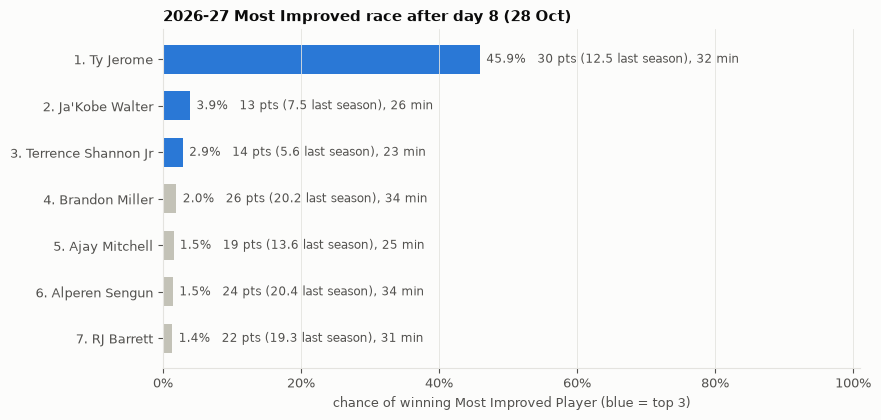

In [6]:
top = T.head(7).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 4.4))
y = np.arange(len(top))
ax.barh(y, top["chance"], color=[BLUE if r <= 3 else MUTED for r in top["rank"]], height=0.62)
for yi, (_, r) in zip(y, top.iterrows()):
    ax.text(r["chance"] + top["chance"].max() * 0.02, yi, f"{r['chance']:.1%}   {r['ppg']:.0f} pts ({r['base_ppg']:.1f} last season), {r['mpg']:.0f} min",
            va="center", fontsize=8.5, color=INK2)
ax.set_yticks(y, [f"{r['rank']}. {r['player_name']}" for _, r in top.iterrows()], fontsize=9.5)
ax.set_xlim(0, top["chance"].max() * 2.2); ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.grid(axis="y", visible=False); ax.set_xlabel("chance of winning Most Improved Player (blue = top 3)")
ax.set_title(f"{LIVE} Most Improved race after day {DAY_NOW} ({live_games['game_date'].max():%d %b})", loc="left")
fig.savefig(FIG_DIR / "12_race_today.png", dpi=150, bbox_inches="tight")

In [7]:
# how our preseason top 7 (notebook 11, preseason through 12 Oct) has started
PRESEASON_TOP7 = ["Reed Sheppard", "Stephon Castle", "Ty Jerome", "Rui Hachimura", "Amen Thompson", "Leonard Miller", "Tristan da Silva"]
rows = []
for i, name in enumerate(PRESEASON_TOP7, 1):
    r = T[T["player_name"] == name]
    played = live_games[live_games["player_name"] == name]
    rows.append({"preseason rank": i, "player": name, "games": len(played),
                 "points": played["pts"].mean() if len(played) else np.nan,
                 "points last season": r["base_ppg"].iloc[0] if len(r) else np.nan,
                 "race rank now": int(r["rank"].iloc[0]) if len(r) else None, "chance now": f"{r['chance'].iloc[0]:.1%}" if len(r) else "not yet a candidate"})
pd.DataFrame(rows).set_index("preseason rank").round(1)

,player,games,points,points last season,race rank now,chance now
preseason rank,,,,,,
1,Reed Sheppard,4,10.5,13.5,58,0.2%
2,Stephon Castle,5,17.4,16.7,47,0.3%
3,Ty Jerome,4,29.8,12.5,1,45.9%
4,Rui Hachimura,3,10.3,11.5,125,0.1%
5,Amen Thompson,5,18.2,18.3,30,0.5%
6,Leonard Miller,5,9.8,7.8,29,0.5%
7,Tristan da Silva,4,14.5,9.9,21,0.6%


### 12B findings (day 8, 28 October; teams have played 3–5 games)

- **Ty Jerome leads clearly (46%).** 29.8 points a game in 31.5 minutes against 12.5 points in 19.9 minutes in his baseline season (2024-25); game score more than doubled (10.7 → 23.8). He was only 16th in our final preseason list (notebook 11). Age (29.6) is what holds him back.
- **Behind him nobody stands out:** Ja'Kobe Walter (3.9%), Terrence Shannon Jr (2.9%), Brandon Miller (2.0%), then Ajay Mitchell, Alperen Sengun and RJ Barrett at about 1.5%.
- **Established scorers are now in the pool and judged by the turning point.** Sengun (20.4 last season), Brandon Miller (20.2) and Zach LaVine (19.2) sit right around it, so their scoring barely counts against them. Anyone well above 20 needs a much bigger jump to show up.
- **Previous winners are in the pool:** Nickeil Alexander-Walker is 114th, because he hasn't improved on his winning season (see 12F).
- **What the model rewards at day 8:** a points jump (+0.83 per SD), baseline scoring up to 20 (+0.51), blocks, game score and assists jumps. Against: points above 20 last season (−0.62), age (−0.78), second-year players (−0.66), and a minutes jump without more production (−0.29).

**Re-run** this notebook at any time; the first cell downloads the latest games.

## 12C — Three snapshots of the 2026-27 race, and the reasons behind each pick

Who did we think would rise most, at three points in time?

1. **End of 2025-26:** last season only (level, role, momentum, age). The 11 model without preseason inputs.
2. **End of preseason:** the 11 model, now with the **full** preseason (11 itself was run on preseason games through 12 October).
3. **Today:** the live race from 12B.

All three snapshots use the same rules: no exclusions, and the scoring turning point at 20 points a game.

**Reasons** are shown two ways: the inputs that pushed each player up most in each model, and plain facts about his situation (role, minutes, points, rebounds, opportunity). The facts are descriptive; "opportunity" (minutes that left his team over the summer) is **not** a model input.

In [8]:
# SNAPSHOTS
from unicorn.preseason import LAST_SEASON_LEAN, MOMENTUM, PROFILE, TURN, USED, add_pool_flags, add_star_left, add_turning_point, load_preseason, preseason_frame

past_games = games[games["season"] != LIVE]
pre = load_preseason(regular=games, refresh_latest=True)            # complete 2026-27 preseason
pre_now = pre[pre["season"] == LIVE]
print(f"{LIVE} preseason: {pre_now['game_id'].nunique()} games, {pre_now['game_date'].min():%d %b} → {pre_now['game_date'].max():%d %b}")

F = add_star_left(add_turning_point(add_pool_flags(preseason_frame(pre, past_games, ps), MIP_WINNERS)), pre, games)   # no exclusions
FH = F[F["season"] != LIVE].reset_index(drop=True)
FT = F[F["season"] == LIVE].reset_index(drop=True)

NICE_PRE = {"mpg_last": "minutes last season", "ppg_last": "points last season", "usg_last": "usage last season",
            "team_win_pct_last": "team's wins last season", "age": "age", "second_year": "second-year discount", "new_team": "new team",
            "momentum_game_score": "improved last season", "late_surge_last": "strong finish last season",
            "pre_game_score_change": "preseason production per 36", "pre_volume_change": "preseason shot volume per 36",
            "pre_ts_change": "preseason shooting", "ppg_over_turn": f"points above {TURNING_POINT} last season",
            "star_left": "a 20-point scorer left (not replaced)"}

def snapshot(train, test, features, nice):
    m = ChoiceModel(features, L2).fit(train)
    out = test[["player_id", "player_name"]].copy()
    out["chance"] = m.predict_proba(test)
    out["rank"] = out["chance"].rank(ascending=False, method="first").astype(int)
    Z = pd.DataFrame(m._design(test), index=test.index, columns=features)
    c = ((Z - Z.mean()) * m.coef_).rename(columns=nice)
    out["model reasons"] = [", ".join(c.drop(columns=["second-year discount", f"points above {TURNING_POINT} last season"]).loc[i].nlargest(2).index) for i in test.index]
    return out.set_index("player_id")

S1 = snapshot(FH, FT, LAST_SEASON_LEAN + PROFILE + MOMENTUM + TURN, NICE_PRE)
S2 = snapshot(FH, FT, USED, NICE_PRE)
S3 = T.set_index("player_id")[["player_name", "chance", "rank", "why"]].rename(columns={"why": "model reasons"})
snaps = {"end of 2025-26": S1, "end of preseason": S2, "today": S3}
for name, s in snaps.items():
    print(f"\n{name}: " + ", ".join(f"{r.player_name} {r.chance:.1%}" for r in s.sort_values("rank").head(7).itertuples()))

2026-27 preseason: 67 games, 03 Oct → 16 Oct



end of 2025-26: Jalen Duren 6.0%, Amen Thompson 4.1%, Stephon Castle 3.7%, Tyrese Haliburton 3.0%, Reed Sheppard 2.0%, Nickeil Alexander-Walker 1.8%, LaMelo Ball 1.6%

end of preseason: Rui Hachimura 9.1%, Jalen Duren 7.9%, Tyrese Haliburton 6.0%, Tristan da Silva 2.4%, Brandon Miller 2.3%, Devin Carter 2.2%, Luka Garza 2.1%

today: Ty Jerome 45.9%, Ja'Kobe Walter 3.9%, Terrence Shannon Jr 2.9%, Brandon Miller 2.0%, Ajay Mitchell 1.5%, Alperen Sengun 1.5%, RJ Barrett 1.4%


In [9]:
# plain facts for every player who made any of the three top 7s
ids = sorted({pid for s in snaps.values() for pid in s.index[s["rank"] <= 7]})
last = past_games[past_games["season_start"] == LIVE_START - 1]
last_team = last.sort_values("game_date").groupby("player_id")["team_id"].last()
last_min = last.groupby("player_id")["min"].sum()
# "baseline season" = the season every model compares against (most recent with 33%+ of the games), not always 2025-26
by_season = past_games.groupby(["player_id", "season_start"]).agg(ppg=("pts", "mean"), rpg=("reb", "mean"), mpg=("min", "mean"))
base_start = F[F["season"] == LIVE].set_index("player_id")["base_season_start"]
L = by_season.reindex(list(zip(base_start.index, base_start.astype(int)))).set_axis(base_start.index)
cur_team = pd.concat([pre_now.sort_values("game_date").groupby("player_id")["team_id"].last(),
                      live_games.sort_values("game_date").groupby("player_id")["team_id"].last()]).groupby(level=0).last()

# opportunity: share of a team's 2025-26 minutes that left over the summer, net of minutes that arrived.
# A team plays 240 minutes a game (5 players x 48), so 25% = a quarter of last season's minutes.
#   left    = players on the team at the end of 2025-26, now seen on another team; only their minutes FOR THAT TEAM
#   arrived = players now on the team who played elsewhere in 2025-26 (all their 2025-26 minutes), excluding the player himself
#   not counted: players not seen in any 2026-27 game yet (injured, unsigned or retired), listed separately
team_min_total = last.groupby("team_id")["min"].sum()
min_for_team = last.groupby(["player_id", "team_id"])["min"].sum()
end_roster = last_team.rename("from").reset_index()
end_roster["min_for_team"] = [min_for_team.get((p, t), 0) for p, t in zip(end_roster["player_id"], end_roster["from"])]
end_roster["to"] = end_roster["player_id"].map(cur_team)
gone = end_roster[end_roster["to"].notna() & (end_roster["to"] != end_roster["from"])]
unseen = end_roster[end_roster["to"].isna()]
newcomers = pd.DataFrame({"player_id": cur_team.index, "to": cur_team.to_numpy()})
newcomers = newcomers[newcomers["player_id"].map(last_team).ne(newcomers["to"]) & newcomers["player_id"].isin(last_min.index)]
newcomers["min"] = newcomers["player_id"].map(last_min)

def team_opportunity(pid):
    """(share of the team's minutes that left, share that arrived excluding him, share held by players not seen yet)"""
    team = cur_team.get(pid)
    if pd.isna(team) or team not in team_min_total.index:
        return np.nan, np.nan, np.nan
    tot = team_min_total[team]
    left_ = gone.loc[gone["from"] == team, "min_for_team"].sum() / tot
    arrived_ = newcomers.loc[(newcomers["to"] == team) & (newcomers["player_id"] != pid), "min"].sum() / tot
    unseen_ = unseen.loc[unseen["from"] == team, "min_for_team"].sum() / tot
    return left_, arrived_, unseen_

pre_rows = F[F["season"] == LIVE].set_index("player_id")
live_rows = T.set_index("player_id")
facts = []
for pid in ids:
    f = pre_rows.loc[pid] if pid in pre_rows.index else None
    l = L.loc[pid] if pid in L.index else None
    t = live_rows.loc[pid] if pid in live_rows.index else None
    name = next(s.loc[pid, "player_name"] for s in snaps.values() if pid in s.index)
    row = {"player": name, **{f"rank: {k}": (int(s.loc[pid, "rank"]) if pid in s.index else np.nan) for k, s in snaps.items()},
           "age": f["age"] if f is not None else (t["age"] if t is not None else np.nan),
           "baseline season": int(base_start[pid]) if pid in base_start.index else np.nan,
           "baseline: points": l["ppg"] if l is not None else np.nan, "baseline: rebounds": l["rpg"] if l is not None else np.nan,
           "baseline: minutes": l["mpg"] if l is not None else np.nan,
           "baseline: usage %": 100 * f["usg_last"] if f is not None else np.nan,
           "baseline: started %": 100 * f["start_rate_last"] if f is not None else np.nan,
           "improved last season (game score)": f["momentum_game_score"] if f is not None else np.nan,
           "finish vs start of last season (game score)": f["late_surge_last"] if f is not None else np.nan,
           "preseason: minutes": f["pre_mpg"] if f is not None else np.nan,
           "preseason: points per 36 vs last season": (f["pts36"] - f["pts36_last"]) if f is not None else np.nan,
           "preseason: shots per 36 vs last season": (f["volume36"] - f["volume36_last"]) if f is not None else np.nan,
           "today: games": t["games"] if t is not None else 0,
           "today: points vs baseline": t["ppg_delta"] if t is not None else np.nan,
           "today: rebounds vs baseline": t["rpg_delta"] if t is not None else np.nan,
           "today: minutes vs baseline": t["mpg_delta"] if t is not None else np.nan,
           "changed team this summer": pid in cur_team.index and pid in last_team.index and cur_team[pid] != last_team[pid],
           **dict(zip(["opportunity: share of team minutes that left", "opportunity: share that arrived",
                                       "opportunity: share held by players not seen yet"], team_opportunity(pid)))}
    facts.append(row)
facts = pd.DataFrame(facts).set_index("player").sort_values("rank: today")

# net opportunity = what left minus what arrived (players not seen yet are NOT counted as gone)
facts["opportunity: net share of team minutes freed"] = facts["opportunity: share of team minutes that left"] - facts["opportunity: share that arrived"]
facts[[c for c in facts.columns if c.startswith("opportunity")]].mul(100).round(0).sort_values("opportunity: net share of team minutes freed", ascending=False)

,opportunity: share of team minutes that left,opportunity: share that arrived,opportunity: share held by players not seen yet,opportunity: net share of team minutes freed
player,,,,
Ajay Mitchell,26.0,5.0,1.0,22.0
LaMelo Ball,31.0,14.0,14.0,17.0
Rui Hachimura,26.0,14.0,18.0,12.0
Terrence Shannon Jr,31.0,24.0,14.0,6.0
Tyrese Haliburton,10.0,10.0,13.0,0.0
Ja'Kobe Walter,16.0,17.0,15.0,-2.0
RJ Barrett,16.0,17.0,15.0,-2.0
Stephon Castle,0.0,2.0,4.0,-2.0
Devin Carter,14.0,17.0,1.0,-3.0


In [10]:
def tags(r):
    """Plain-language reasons from the facts table (descriptive thresholds, not model inputs)."""
    t = []
    if r["age"] < 24: t.append(f"young ({r['age']:.0f})")
    if r["baseline: minutes"] >= 30: t.append(f"already {r['baseline: minutes']:.0f} min")
    elif r["baseline: minutes"] < 20: t.append(f"bench role last season ({r['baseline: minutes']:.0f} min)")
    if r["baseline: started %"] < 25: t.append("came off the bench")
    if r["improved last season (game score)"] >= 1.5: t.append("improving already")
    if r["finish vs start of last season (game score)"] >= 1.5: t.append("strong finish to last season")
    if r["preseason: minutes"] - r["baseline: minutes"] >= 4: t.append(f"preseason minutes up ({r['preseason: minutes']:.0f})")
    if r["preseason: shots per 36 vs last season"] >= 3: t.append("shooting more in preseason")
    if r["changed team this summer"]: t.append("new team")
    if r["opportunity: net share of team minutes freed"] >= 0.15: t.append(f"{r['opportunity: net share of team minutes freed']:.0%} of his team's minutes freed up")
    if r["today: points vs baseline"] >= 5: t.append(f"+{r['today: points vs baseline']:.0f} points so far")
    if r["today: rebounds vs baseline"] >= 3: t.append(f"+{r['today: rebounds vs baseline']:.0f} rebounds so far")
    if r["today: minutes vs baseline"] >= 6: t.append(f"+{r['today: minutes vs baseline']:.0f} minutes so far")
    return " · ".join(t)

facts["situation"] = facts.apply(tags, axis=1)
reasons = pd.DataFrame({f"why {k}": [s.loc[pid, "model reasons"] if pid in s.index else "" for pid in ids] for k, s in snaps.items()},
                       index=[facts.index[list(facts.index).index(n)] for n in [next(s.loc[pid, 'player_name'] for s in snaps.values() if pid in s.index) for pid in ids]])
facts.join(reasons)[["rank: end of 2025-26", "rank: end of preseason", "rank: today", "situation", *reasons.columns]]

,rank: end of 2025-26,rank: end of preseason,rank: today,situation,why end of 2025-26,why end of preseason,why today
player,,,,,,,
Ty Jerome,20,16,1.0,bench role last season (20 min) · came off the...,"team's wins last season, strong finish last se...","preseason shot volume per 36, team's wins last...",points + game score
Ja'Kobe Walter,69,115,2.0,young (22) · strong finish to last season · sh...,"strong finish last season, age","strong finish last season, age",points + age
Terrence Shannon Jr,189,152,3.0,bench role last season (12 min) · came off the...,"strong finish last season, team's wins last se...","preseason shot volume per 36, strong finish la...",points + game score
Brandon Miller,24,5,4.0,already 30 min · improving already · +5 points...,"minutes last season, usage last season","a 20-point scorer left (not replaced), minutes...",points + age
Ajay Mitchell,36,116,5.0,improving already · shooting more in preseason...,"team's wins last season, improved last season","team's wins last season, improved last season",points + age
Alperen Sengun,22,47,6.0,already 33 min,"minutes last season, team's wins last season","minutes last season, age",points + baseline scoring
RJ Barrett,53,52,7.0,already 30 min,"minutes last season, usage last season","minutes last season, usage last season",points + baseline scoring
Tyrese Haliburton,4,3,10.0,already 34 min · strong finish to last season ...,"strong finish last season, minutes last season","preseason shot volume per 36, strong finish la...",points + baseline scoring
Tristan da Silva,44,4,21.0,improving already · strong finish to last seas...,"strong finish last season, age","preseason shot volume per 36, strong finish la...",points + game score


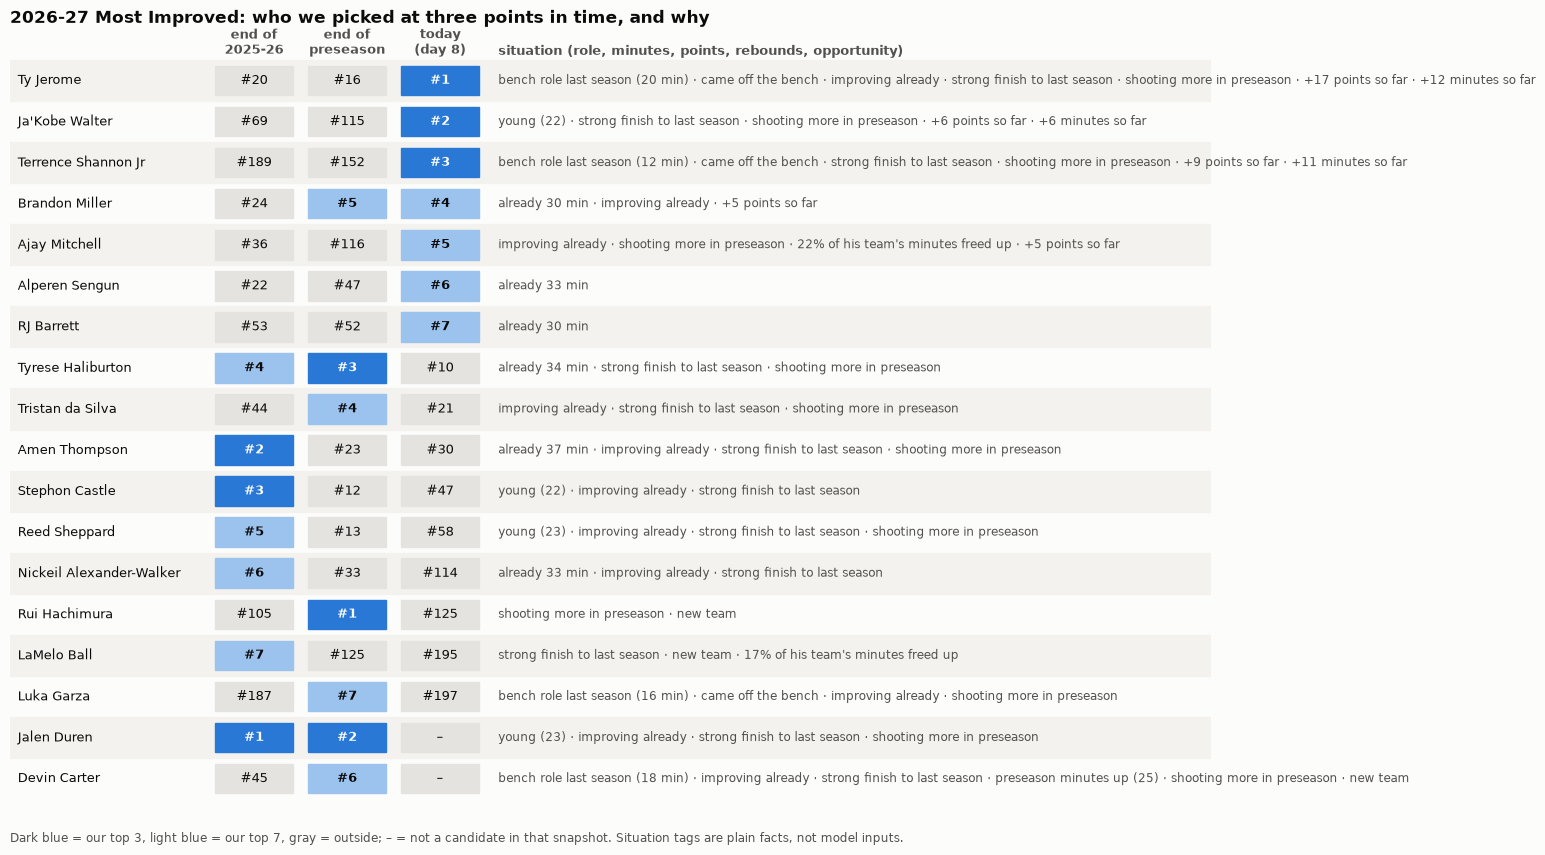

In [11]:
fig_rows = facts.sort_values(["rank: today"]).copy()
n = len(fig_rows)
fig, ax = plt.subplots(figsize=(15.5, 0.48 * n + 1.6))
ax.set_xlim(0, 15.5); ax.set_ylim(n, -1.2); ax.axis("off")
cols_x = {"end of 2025-26": 3.15, "end of preseason": 4.35, "today": 5.55}
for x, label in zip(cols_x.values(), ["end of\n2025-26", "end of\npreseason", f"today\n(day {DAY_NOW})"]):
    ax.text(x, -0.55, label, ha="center", va="bottom", fontsize=9, color=INK2, fontweight="bold")
ax.text(6.3, -0.55, "situation (role, minutes, points, rebounds, opportunity)", ha="left", va="bottom", fontsize=9, color=INK2, fontweight="bold")
for i, (name, r) in enumerate(fig_rows.iterrows()):
    if i % 2 == 0:
        ax.add_patch(plt.Rectangle((0, i - 0.5), 15.5, 1, color="#f3f2ee", zorder=0))
    ax.text(0.1, i, name, va="center", fontsize=9.5, color=INK)
    for k, x in cols_x.items():
        rk = r[f"rank: {k}"]
        top = pd.notna(rk) and rk <= 7
        ax.add_patch(plt.Rectangle((x - 0.5, i - 0.36), 1.0, 0.72, color=(BLUE if pd.notna(rk) and rk <= 3 else "#9cc3ee" if top else "#e4e3df"), zorder=1))
        ax.text(x, i, "–" if pd.isna(rk) else f"#{int(rk)}", ha="center", va="center", fontsize=9, zorder=2,
                color=SURFACE if pd.notna(rk) and rk <= 3 else INK, fontweight="bold" if top else "normal")
    ax.text(6.3, i, r["situation"], va="center", fontsize=8.3, color=INK2)
ax.set_title(f"{LIVE} Most Improved: who we picked at three points in time, and why", loc="left", fontsize=12, x=0)
ax.text(0, n + 0.3, "Dark blue = our top 3, light blue = our top 7, gray = outside; – = not a candidate in that snapshot. "
        "Situation tags are plain facts, not model inputs.", fontsize=8.5, color=INK2, va="top")
fig.savefig(FIG_DIR / "12_three_snapshots.png", dpi=150, bbox_inches="tight")

### 12C findings (day 8, 28 October; revised rules)

**End of 2025-26: young players already playing big minutes and already improving.** Jalen Duren, Amen Thompson, Stephon Castle, Tyrese Haliburton, Reed Sheppard, Nickeil Alexander-Walker (now allowed as a previous winner), LaMelo Ball. This model has no information about the summer, so it can only extend last season's trend.

**End of preseason: the summer's moves reshape the list.** Rui Hachimura (Kawhi Leonard left the Clippers) moves to #1, ahead of Duren and Haliburton; Brandon Miller (LaMelo Ball left Charlotte), Devin Carter and Luka Garza (Jaylen Brown left Boston) come in on the star flag, plus Tristan da Silva. This is the list in notebook 11.

**Today: a new list, with one exception.** **Brandon Miller** is the only player in both the preseason and today top 7 (5th and 4th): 25.6 points a game against 20.2. Ty Jerome, today's clear leader, was 16th at the end of preseason. Ja'Kobe Walter and Terrence Shannon Jr were outside the top 100 at both earlier points.
- **Jalen Duren and Devin Carter are not candidates right now:** each has missed too many of his team's games so far (Duren has played 2 of Detroit's 5). They re-enter once they play enough.
- **Hachimura, #1 before the season, is 125th:** 10.3 points in 3 games, against 11.5 last season.
- Of the other earlier favourites, Haliburton (10th) and da Silva (21st) are closest.
- The 5-season backtest below says pre-season lists catch the winner in about 2 seasons in 5, so "Jerome has the best start" is the right reading, not "Jerome will win".

**Reasons, by type**
- **Role:** today's risers mostly came off the bench last season (Jerome, Shannon). The earlier lists favoured players who already started and played 30+ minutes, or who inherit a departed star's role.
- **Minutes:** the movers have gained minutes (Jerome +12, Shannon +11), and points have come with them.
- **Points and rebounds:** the model leans on points and game score; rebounds barely count (Hachimura +2.7 rebounds, 125th).
- **Opportunity:** the share of his team's 2025-26 minutes that left over the summer, minus the share brought in (players on the team at the end of last season, counting only minutes they played for that team; the player's own minutes excluded; players not seen in any game yet are not counted as gone). Most freed up: Ajay Mitchell's Thunder (22%) and LaMelo Ball's team (17%). Ty Jerome's team brought in more than it lost (−12%), so his rise is not about vacated minutes. Tested as a preseason input: it adds nothing beyond the star flag; shown as a fact only.

*Correction (30 October):* an earlier version showed opportunity as "minutes per game that left his team" (e.g. "62 min/game"). That was team minutes per game out of 240, not a player's minutes; it also counted players not yet seen as gone, gave traded players' whole season to their last team, and included the player's own minutes as an arrival. All four are fixed.

## 12D — Backtest: the same views for the last five seasons

For each season from 2021-22 to 2025-26, four lists:
1. **End of the previous season:** last season only (the 11 model without preseason inputs).
2. **End of preseason:** the 11 model.
3. **Mid-season:** the 12 race at **day 85** (about halfway through a normal season, mid-January).
4. **What actually happened:** the real voting top 7 (Basketball-Reference, used only to score our lists).

**Strict test:** every list comes from a model trained only on **earlier** seasons, so it is what we would have said at the time. Candidate rules are the same as above (no exclusions, scoring turning point at 20).

In [12]:
# FIVE_SEASONS
from unicorn.bref import all_mip_voting, attach_player_ids

BACK = ["2021-22", "2022-23", "2023-24", "2024-25", "2025-26"]
DAY_MID = 85
votes = attach_player_ids(all_mip_voting(), games)
mid = race(DAY_MID)
FA = F[F["season"] != LIVE]

def walk_forward(train_all, test_all, features, season):
    m = ChoiceModel(features, L2).fit(train_all[train_all["season"] < season])
    t = test_all[test_all["season"] == season]
    out = t[["player_id", "player_name", "mip"]].assign(chance=m.predict_proba(t))
    out["rank"] = out["chance"].rank(ascending=False, method="first").astype(int)
    return out.sort_values("rank")

VIEWS = {"end of previous season": lambda s: walk_forward(FH, FA, LAST_SEASON_LEAN + PROFILE + MOMENTUM + TURN, s),
         "end of preseason": lambda s: walk_forward(FH, FA, USED, s),
         f"mid-season (day {DAY_MID})": lambda s: walk_forward(mid[mid["season"] != LIVE], mid, EARLY, s)}
lists = {(s, v): f(s) for s in BACK for v, f in VIEWS.items()}

rows = []
for s in BACK:
    real = votes[(votes["season"] == s) & (votes["vote_rank"] <= 7)]
    voted = set(votes.loc[votes["season"] == s, "player_id"].dropna().astype(int))
    winner = real.loc[real["vote_rank"] == 1, "player"].iloc[0]
    for v in VIEWS:
        L7 = lists[(s, v)]
        w = L7[L7["mip"]]
        top = L7.head(7)
        rows.append({"season": s, "view": v, "winner": winner, "winner's rank": int(w["rank"].iloc[0]) if len(w) else None,
                     "of our 7 in the real top 7": int(top["player_id"].isin(real["player_id"]).sum()),
                     "of our 7 who got any vote": int(top["player_id"].isin(voted).sum())})
scores = pd.DataFrame(rows)
summary = scores.groupby("view", sort=False).agg(**{"winner in our top 7 (of 5)": ("winner's rank", lambda r: int((r <= 7).sum())),
                                                   "median winner rank": ("winner's rank", "median"),
                                                   "of our 7 in the real top 7 (avg)": ("of our 7 in the real top 7", "mean"),
                                                   "of our 7 who got any vote (avg)": ("of our 7 who got any vote", "mean")})
display(scores.pivot(index="season", columns="view", values="winner's rank")[list(VIEWS)].rename_axis(columns="winner's rank in each view"))
summary.round(1)

winner's rank in each view,end of previous season,end of preseason,mid-season (day 85)
season,,,
2021-22,45,15,1
2022-23,43,4,1
2023-24,4,19,2
2024-25,53,6,10
2025-26,44,26,5


,winner in our top 7 (of 5),median winner rank,of our 7 in the real top 7 (avg),of our 7 who got any vote (avg)
view,,,,
end of previous season,1,44.0,0.6,1.2
end of preseason,2,15.0,0.8,1.0
mid-season (day 85),4,2.0,3.0,3.2


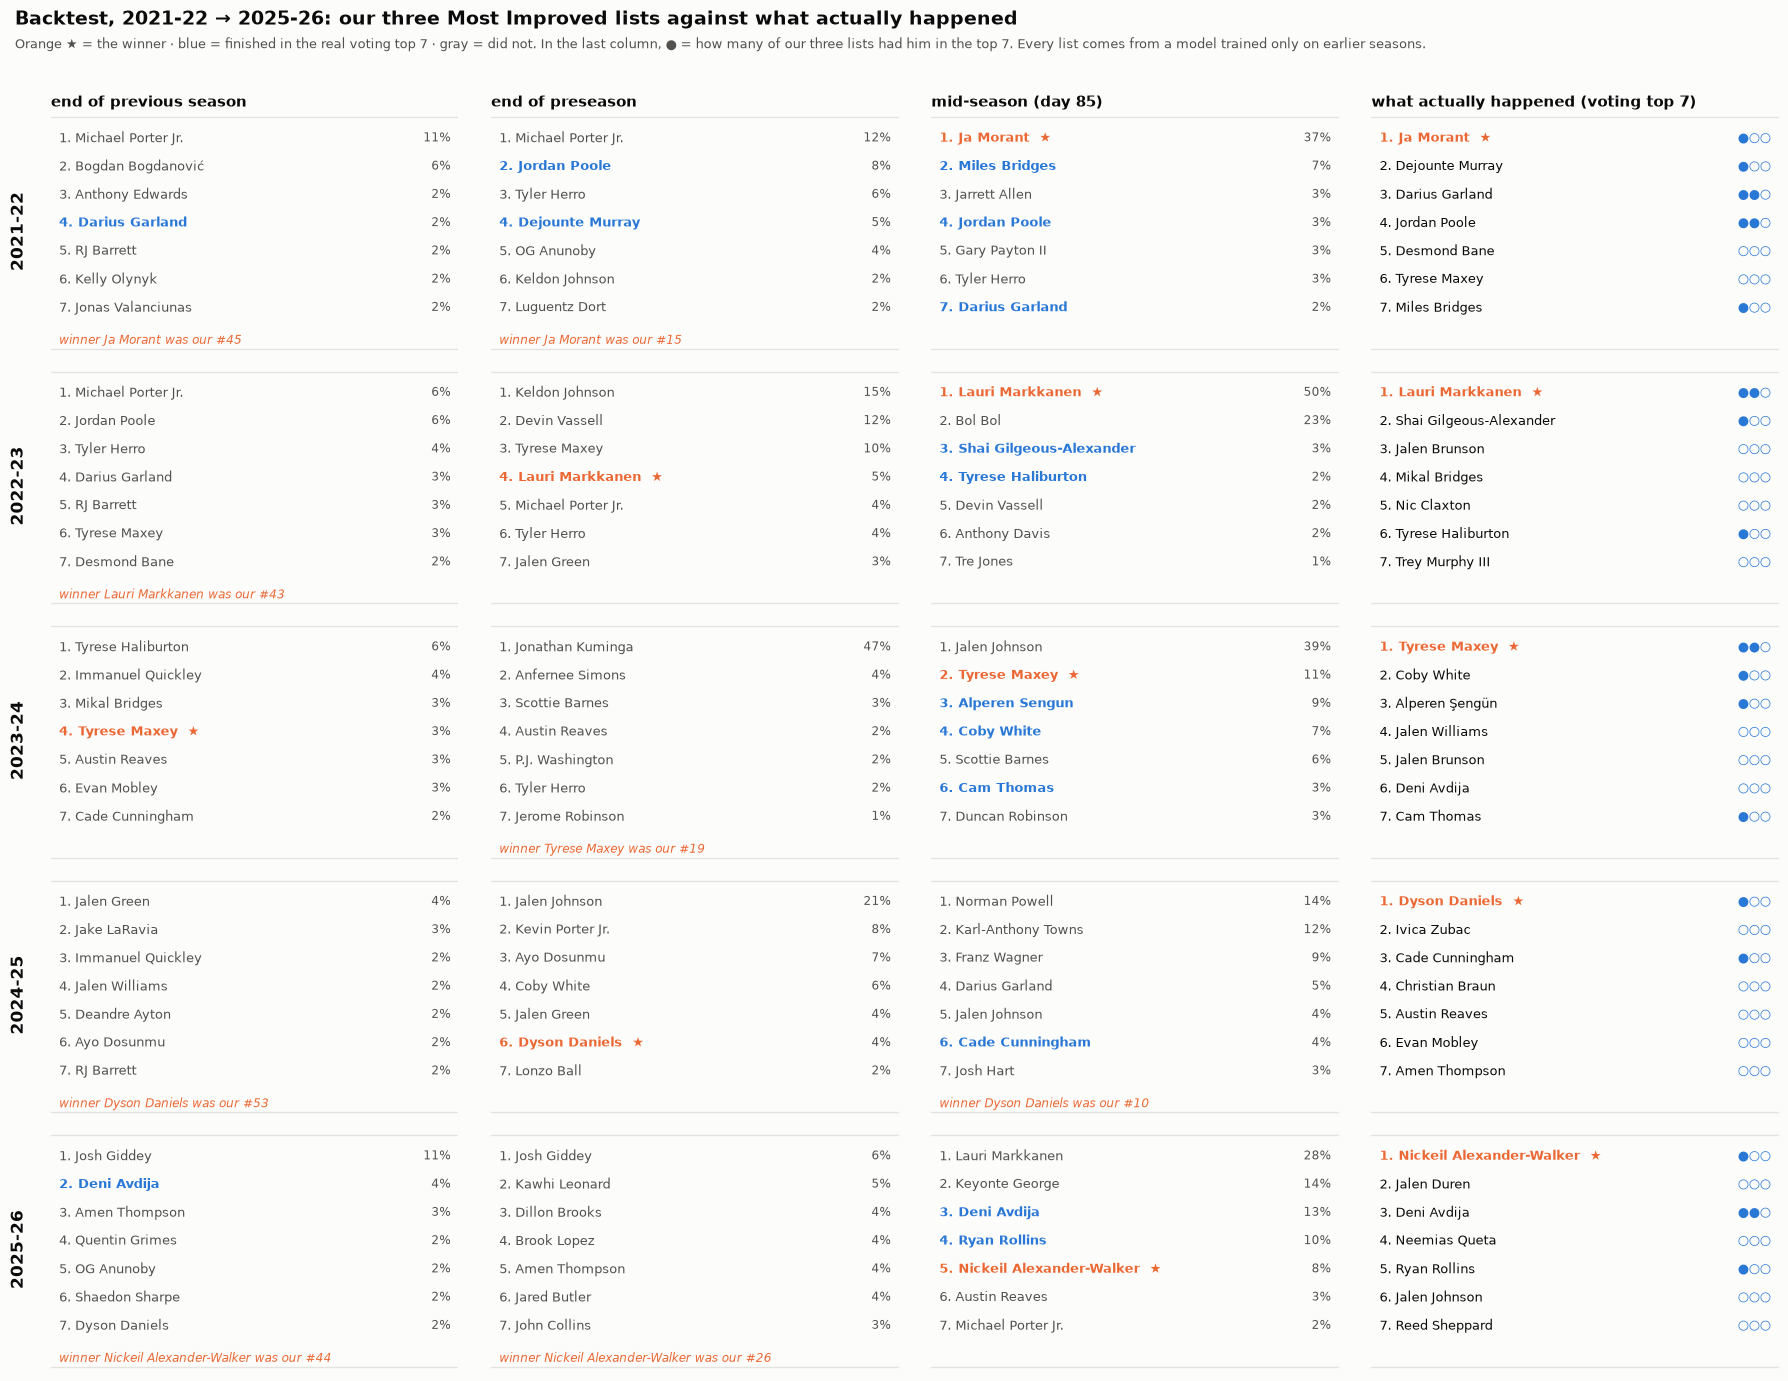

In [13]:
fig, axes = plt.subplots(len(BACK), 4, figsize=(18, 2.55 * len(BACK) + 1.0))
heads = list(VIEWS) + ["what actually happened (voting top 7)"]
for i, s in enumerate(BACK):
    real = votes[(votes["season"] == s)].sort_values("vote_rank").head(7)
    real_ids = set(real["player_id"].dropna().astype(int))
    ours = [set(lists[(s, v)].head(7)["player_id"]) for v in VIEWS]
    for j in range(4):
        ax = axes[i, j]; ax.axis("off"); ax.set_xlim(0, 1); ax.set_ylim(7.6, -0.9)
        if i == 0:
            ax.text(0, -1.0, heads[j], fontsize=10.5, fontweight="bold", color=INK, va="bottom")
        if j == 0:
            ax.text(-0.08, 3.3, s, fontsize=12, fontweight="bold", color=INK, rotation=90, va="center", ha="center")
        if j < 3:
            L7 = lists[(s, list(VIEWS)[j])]
            for k, r in enumerate(L7.head(7).itertuples()):
                hit = r.player_id in real_ids
                col = ORANGE if r.mip else (BLUE if hit else INK2)
                ax.text(0.02, k, f"{r.rank}. {r.player_name}{'  ★' if r.mip else ''}", fontsize=9.3, color=col,
                        fontweight="bold" if (hit or r.mip) else "normal", va="center")
                ax.text(0.98, k, f"{r.chance:.0%}", fontsize=8.5, color=INK2, va="center", ha="right")
            w = L7[L7["mip"]]
            if len(w) and int(w["rank"].iloc[0]) > 7:
                ax.text(0.02, 7.15, f"winner {w['player_name'].iloc[0]} was our #{int(w['rank'].iloc[0])}", fontsize=8.3, color=ORANGE, va="center", style="italic")
            elif not len(w):
                ax.text(0.02, 7.15, "winner was not a candidate in this view", fontsize=8.3, color=ORANGE, va="center", style="italic")
        else:
            for k, r in enumerate(real.itertuples()):
                pid = int(r.player_id) if pd.notna(r.player_id) else -1
                n_lists = sum(pid in o for o in ours)
                ax.text(0.02, k, f"{r.vote_rank}. {r.player}{'  ★' if r.vote_rank == 1 else ''}", fontsize=9.3,
                        color=ORANGE if r.vote_rank == 1 else INK, fontweight="bold" if r.vote_rank == 1 else "normal", va="center")
                ax.text(0.98, k, "●" * n_lists + "○" * (3 - n_lists), fontsize=9, color=BLUE, va="center", ha="right")
        ax.add_patch(plt.Rectangle((-0.02, -0.75), 1.04, 8.2, fill=False, edgecolor="#e4e3df", linewidth=1))
fig.suptitle("Backtest, 2021-22 → 2025-26: our three Most Improved lists against what actually happened", x=0.01, y=1.0, ha="left", fontsize=14, fontweight="bold")
fig.text(0.01, 0.972, "Orange ★ = the winner · blue = finished in the real voting top 7 · gray = did not. In the last column, ● = how many of our three lists had him in the top 7. "
         "Every list comes from a model trained only on earlier seasons.", ha="left", fontsize=9.5, color=INK2)
fig.subplots_adjust(left=0.03, right=0.99, top=0.925, bottom=0.01, wspace=0.08, hspace=0.06)
fig.savefig(FIG_DIR / "12_backtest_five_seasons.png", dpi=150, bbox_inches="tight")

### 12D findings (revised rules: no exclusions, scoring turning point at 20, star flag)

| View (strict, 5 seasons) | Winner in our top 7 | Median winner rank | Of our 7 in the real voting top 7 | Of our 7 who got any vote |
|---|---|---|---|---|
| End of previous season | 1 of 5 | 44 | 0.6 | 1.2 |
| End of preseason | 2 of 5 | 15 | 0.8 | 1.0 |
| **Mid-season (day 85)** | **4 of 5** | **2** | **3.0** | **3.2** |

- **By mid-January the race is usually decided.** The eventual winner was #1 twice (Ja Morant, Lauri Markkanen), #2 once (Tyrese Maxey) and #5 once (Nickeil Alexander-Walker). Dyson Daniels was 10th. Three of our seven, on average, finished in the real voting top 7.
- **The revision cost one season here:** with the old rules (previous winners and 22+ scorers excluded) the winner was in the mid-January top 7 in all 5 seasons; Daniels was 4th rather than 10th. The revised pool adds players the old rules left out, and some of them outrank him in January.
- **Before a game is played, we catch some.** The end-of-season list caught Maxey (2023-24, #4); the preseason list, now with the star flag, caught Markkanen (#4; Donovan Mitchell had left Utah) and Daniels (#6; Dejounte Murray had left Atlanta).
- **Preseason moves the winner up in 4 of 5 seasons** (Morant 45 → 15, Markkanen 43 → 4, Daniels 53 → 6, Alexander-Walker 44 → 26). The exception is Maxey (4 → 19).
- **A new role is the key pre-season clue.** Markkanen and Daniels were traded into teams that had just lost their star; the star flag sees that. Alexander-Walker (26th) and Maxey (19th; James Harden left only after the season began) are the ones it can't see.
- **For 2026-27:** read the end-of-season and preseason lists as "who is set up to improve", not "who will win", and check back around mid-January.

## 12E — The daily leaderboard, and how it has moved

One leaderboard for **every day of the season**, built as if we had run it that evening:
- **Day 1 = opening night.** Day *n* uses only games played on days 1 to *n*.
- **The model for day *n*** is trained on past seasons cut at the same day *n*, so every day's chances are what we would have said at the time.
- **Days are saved once and never recomputed** (`data/processed/mip_race_daily_2026_27.parquet`). Each re-run adds only the new days. If the model settings change, the file is rebuilt from day 1.

The chart at the end is the "worm": each player's rank, day by day.

In [14]:
# DAILY_BOARD
DAILY_PATH = PROJECT_ROOT / "data" / "processed" / "mip_race_daily_2026_27.parquet"
SETTINGS = f"features={EARLY}|l2={L2}|rules=1+ prior season, half of team games, previous winners included, turning point {TURNING_POINT}"

def board_for_day(day_index):
    """Full leaderboard after `day_index` days (0 = opening night), using only games up to that day."""
    c = race(day_index)
    h, t = c[c["season"] != LIVE], c[c["season"] == LIVE].copy()
    t["chance"] = ChoiceModel(EARLY, L2).fit(h).predict_proba(t)
    t["rank"] = t["chance"].rank(ascending=False, method="first").astype(int)
    t["day"] = day_index + 1
    t["date"] = live_games["game_date"].min() + pd.Timedelta(days=day_index)
    return t[["day", "date", "player_id", "player_name", "team", "games", "ppg", "base_ppg", "game_score", "base_game_score", "mpg", "base_mpg", "chance", "rank"]]

daily = pd.read_parquet(DAILY_PATH) if DAILY_PATH.exists() else pd.DataFrame()
if len(daily) and (daily["settings"].iloc[0] != SETTINGS):
    print("model settings changed: rebuilding from day 1"); daily = pd.DataFrame()
done = set(daily["day"]) if len(daily) else set()
new = [board_for_day(d).assign(settings=SETTINGS) for d in range(DAY_NOW + 1) if d + 1 not in done]
if new:
    daily = pd.concat([daily, *new], ignore_index=True).sort_values(["day", "rank"])
    daily.to_parquet(DAILY_PATH, index=False)
print(f"days on file: 1–{daily['day'].max()} (added {len(new)} today)")

top7 = daily[daily["rank"] <= 7].pivot(index="rank", columns="day", values="player_name")
top7.columns = [f"day {d} ({daily.loc[daily['day'] == d, 'date'].iloc[0]:%d %b})" for d in top7.columns]
top7

days on file: 1–9 (added 0 today)


,day 1 (20 Oct),day 2 (21 Oct),day 3 (22 Oct),day 4 (23 Oct),day 5 (24 Oct),day 6 (25 Oct),day 7 (26 Oct),day 8 (27 Oct),day 9 (28 Oct)
rank,,,,,,,,,
1,Jared McCain,Ty Jerome,Ty Jerome,Ty Jerome,Ty Jerome,Ty Jerome,Ty Jerome,Ty Jerome,Ty Jerome
2,Paul George,Jabari Smith Jr.,Jabari Smith Jr.,Walker Kessler,Walker Kessler,Ja'Kobe Walter,Ja'Kobe Walter,Ja'Kobe Walter,Ja'Kobe Walter
3,Dylan Harper,Yves Missi,Yves Missi,Tyler Herro,Jaxson Hayes,Amen Thompson,Zaccharie Risacher,Terrence Shannon Jr,Terrence Shannon Jr
4,Jalen Duren,Walker Kessler,Paolo Banchero,Alperen Sengun,Scottie Barnes,Franz Wagner,Zach LaVine,Alperen Sengun,Brandon Miller
5,Ausar Thompson,Jalen Duren,Naz Reid,Scottie Barnes,Ja'Kobe Walter,Zach LaVine,Terrence Shannon Jr,Zaccharie Risacher,Ajay Mitchell
6,Andre Drummond,Naz Reid,Tyler Herro,Jaxson Hayes,Davion Mitchell,Alperen Sengun,Brandon Miller,Brandon Miller,Alperen Sengun
7,Julian Champagnie,Paolo Banchero,Walker Kessler,Naz Reid,Zaccharie Risacher,Terrence Shannon Jr,Franz Wagner,Franz Wagner,RJ Barrett


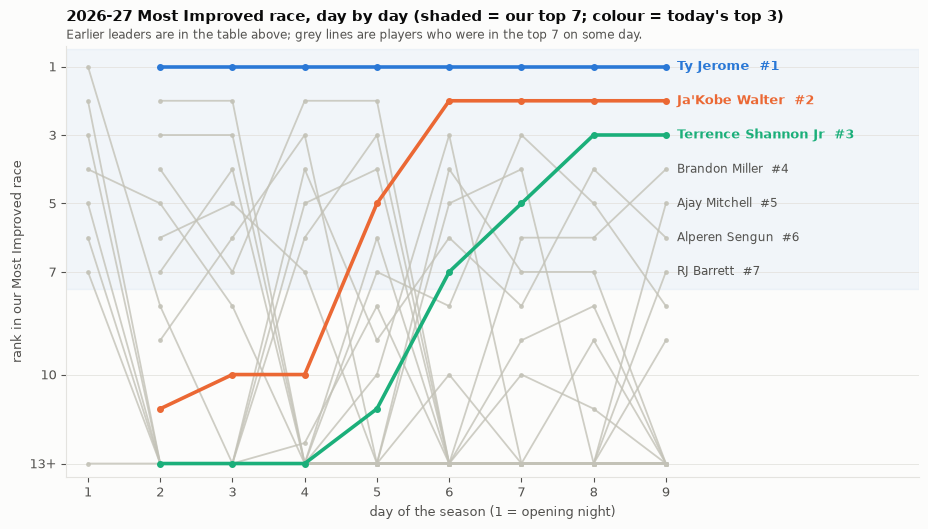

In [15]:
# worm chart: rank by day for everyone who has been in the top 7; the current top 3 in colour
ever = daily.loc[daily["rank"] <= 7, "player_id"].unique()
last_day = daily["day"].max()
now_top3 = daily[(daily["day"] == last_day)].nsmallest(3, "rank")["player_id"].tolist()
colours = dict(zip(now_top3, [BLUE, ORANGE, SERIES[2]]))
SHOW = 12                                     # ranks below this are drawn at the bottom edge
fig, ax = plt.subplots(figsize=(11, 5.6))
for pid in ever:
    d = daily[daily["player_id"] == pid].set_index("day")["rank"].reindex(range(1, last_day + 1))
    y = d.clip(upper=SHOW + 0.6)
    top = pid in colours
    ax.plot(y.index, y, color=colours.get(pid, MUTED), linewidth=2.6 if top else 1.3, alpha=1 if top else 0.8,
            marker="o", markersize=4 if top else 2.5, zorder=3 if top else 2)
    last = d.dropna()
    name = daily.loc[daily["player_id"] == pid, "player_name"].iloc[0]
    if top:
        ax.annotate(f"{name}  #{int(d.iloc[-1])}", (last_day, min(d.iloc[-1], SHOW + 0.6)), xytext=(8, 0), textcoords="offset points",
                    va="center", fontsize=9.5, color=colours[pid], fontweight="bold")
    elif pd.notna(d.iloc[-1]) and d.iloc[-1] <= 7:   # the rest of today's top 7, named at the right edge
        ax.annotate(f"{name}  #{int(d.iloc[-1])}", (last_day, d.iloc[-1]), xytext=(8, 0), textcoords="offset points",
                    va="center", fontsize=8.5, color=INK2)
ax.axhspan(0.5, 7.5, color=BLUE, alpha=0.05, zorder=0)
ax.set_ylim(SHOW + 1, 0.4); ax.set_yticks([1, 3, 5, 7, 10, SHOW + 0.6], ["1", "3", "5", "7", "10", f"{SHOW + 1}+"])
ax.set_xlim(0.7, last_day + 3.5); ax.set_xticks(range(1, last_day + 1))
ax.set_xlabel("day of the season (1 = opening night)"); ax.set_ylabel("rank in our Most Improved race")
ax.grid(axis="x", visible=False)
ax.set_title(f"{LIVE} Most Improved race, day by day (shaded = our top 7; colour = today's top 3)", loc="left", pad=18)
ax.text(0, 1.01, "Earlier leaders are in the table above; grey lines are players who were in the top 7 on some day.", transform=ax.transAxes, fontsize=8.5, color=INK2, va="bottom")
fig.savefig(FIG_DIR / "12_daily_worm.png", dpi=150, bbox_inches="tight")

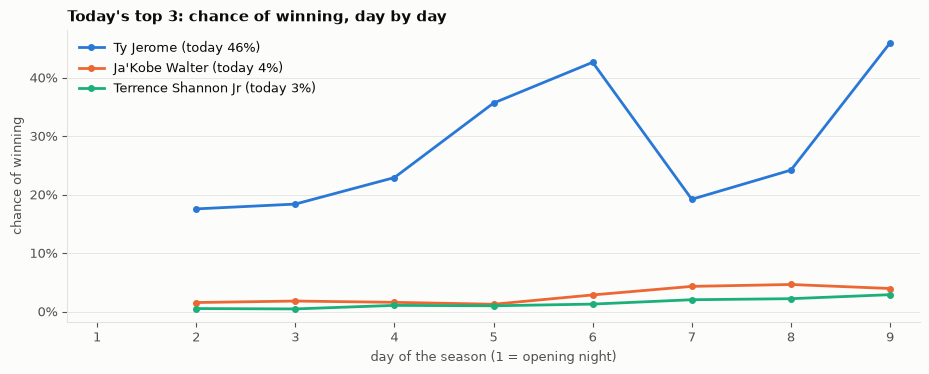

In [16]:
# the same story in chances: today's top 3 against the rest of the field
fig, ax = plt.subplots(figsize=(11, 3.8))
for pid in now_top3:
    d = daily[daily["player_id"] == pid].set_index("day")["chance"].reindex(range(1, last_day + 1))
    name = daily.loc[daily["player_id"] == pid, "player_name"].iloc[0]
    ax.plot(d.index, d, color=colours[pid], marker="o", markersize=4, label=f"{name} (today {d.iloc[-1]:.0%})")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); ax.set_xticks(range(1, last_day + 1)); ax.set_xlim(0.7, last_day + 0.3)
ax.set_xlabel("day of the season (1 = opening night)"); ax.set_ylabel("chance of winning")
ax.legend(frameon=False, loc="upper left"); ax.grid(axis="x", visible=False)
ax.set_title("Today's top 3: chance of winning, day by day", loc="left")
fig.savefig(FIG_DIR / "12_daily_chance.png", dpi=150, bbox_inches="tight")

### 12E findings (day 9 = 28 October)

- **Counting note:** this section counts opening night as day 1, so day 9 here is "day 8 after opening night" in the sections above.
- **The daily file was rebuilt from day 1 on 30 October** because the rules changed (previous winners in, scoring turning point at 20). Each day still uses only games up to that day.
- **Opening night (day 1) had only two games,** so the first leaderboard is four teams' players: Jared McCain, Paul George, Dylan Harper.
- **Ty Jerome has led every day since his first game (day 2).** Nobody else has held #1.
- **Below him the board has turned over almost completely.** Of the seven names on day 2, none except Jerome is in today's top 7. Ja'Kobe Walter has held #2 for four days; Terrence Shannon Jr has been #3 for two.
- **Chances move more than ranks.** Each day's model is trained separately on past seasons cut at that day, and with only a few games per player the weights shift from day to day. **Read the ranks for the trend and the chances for the size of the lead.**

**How to keep it going:** re-run this notebook (top to bottom) whenever you like. It adds every day since the last run and redraws both charts; days already on file are never recomputed unless the model settings change.

## 12F — Do Most Improved leaps last? (Nickeil Alexander-Walker, 2025-26 winner)

Each past winner's scoring the season before he won, the season he won, and the season after. For the latest winner, "the season after" is 2026-27 so far. **Revisit at the All-Star break.**

In [17]:

# LEAPS
season_ppg = games.groupby(["player_id", "season_start"]).agg(ppg=("pts", "mean"), games_played=("game_id", "size"), name=("player_name", "last"))
rows = []
for s, pid in MIP_WINNERS.items():
    y = int(s[:4])
    get = lambda k, col: season_ppg.loc[(pid, k), col] if (pid, k) in season_ppg.index else np.nan
    rows.append({"season won": s, "player": get(y, "name"), "points the season before": get(y - 1, "ppg"), "points in the winning season": get(y, "ppg"),
                 "points the season after": get(y + 1, "ppg"), "games the season after": get(y + 1, "games_played")})
leaps = pd.DataFrame(rows).set_index("season won")
leaps["change the season after"] = leaps["points the season after"] - leaps["points in the winning season"]
leaps["share of the leap kept"] = ((leaps["points the season after"] - leaps["points the season before"])
                                   / (leaps["points in the winning season"] - leaps["points the season before"]))
past = leaps.drop(index=LIVE.replace("2026-27", "2025-26"))
print(f"past winners: median change the season after {past['change the season after'].median():+.1f} points; "
      f"{(past['share of the leap kept'] >= 0.8).sum()} of {len(past)} kept at least 80% of their leap; "
      f"{(past['share of the leap kept'] < 0.5).sum()} kept less than half")
latest = leaps.loc["2025-26"]
print(f"{latest['player']}: {latest['points the season before']:.1f} → {latest['points in the winning season']:.1f} → {latest['points the season after']:.1f} "
      f"in {int(latest['games the season after'])} games of {LIVE} ({latest['share of the leap kept']:.0%} of the leap kept so far)")
leaps.round(2)


past winners: median change the season after +0.0 points; 9 of 14 kept at least 80% of their leap; 3 kept less than half
Nickeil Alexander-Walker: 9.4 → 20.8 → 19.6 in 5 games of 2026-27 (89% of the leap kept so far)


,player,points the season before,points in the winning season,points the season after,games the season after,change the season after,share of the leap kept
season won,,,,,,,
2011-12,Ryan Anderson,10.64,16.07,16.16,81,0.09,1.02
2012-13,Paul George,12.09,17.43,21.71,80,4.28,1.80
2013-14,Goran Dragic,14.73,20.29,16.35,78,-3.94,0.29
2014-15,Jimmy Butler III,13.10,20.02,20.88,67,0.87,1.13
2015-16,CJ McCollum,6.84,20.82,22.96,80,2.14,1.15
2016-17,Giannis Antetokounmpo,16.88,22.90,26.85,75,3.95,1.66
2017-18,Victor Oladipo,15.93,23.13,18.75,36,-4.38,0.39
2018-19,Pascal Siakam,7.27,16.92,22.85,60,5.93,1.61
2019-20,Brandon Ingram,18.27,23.82,23.77,61,-0.05,0.99


### 12F findings

- **Most leaps last.** The typical winner scored the same the next season (median change +0.0 points). 9 of 14 kept at least 80% of their jump, and four kept improving (Paul George, Giannis Antetokounmpo, Pascal Siakam, CJ McCollum).
- **Three collapsed:** Goran Dragić, Victor Oladipo (injured, 36 games) and Julius Randle each fell back by about 4 points, keeping under 40% of their leap.
- **Nickeil Alexander-Walker so far:** 9.4 → 20.8 → **19.6** points a game in 5 games of 2026-27, 89% of his leap kept. On track to be a "real" leap, but 5 games is nothing.
- **Revisit at the All-Star break** (about 50 games in): by then a fall like Dragić's or Randle's would be visible.